# Short-Term Rental Guest Feedback: Phase 2

INFO 4360 course project. Path B: find what guests complain about, where and when, so the COO knows what to fix first.

Data: Inside Airbnb, Broward County, FL (2026-06-29). The raw files are not in this repo, see `data/README.md`.

## 0. Setup

Load packages and our helper functions

In [1]:
import sys
sys.path.append("..")   # lets the notebook import from src/

import pandas as pd
import matplotlib.pyplot as plt

from src.preprocessing import strip_html, clean_text, looks_english, load_reviews

RAW = "../data/raw"   # reviews.csv.gz and listings.csv.gz go here

## 1. Data exploration

### 1.1 Size

In [2]:
# One row per review, with the details of its listing
df = load_reviews(RAW)

print("Reviews:", len(df))
print("Listings:", df["listing_id"].nunique())
print("Dates:", df["date"].min().date(), "to", df["date"].max().date())
df.drop(columns="comments").head(3)   # review text left out on purpose (public repo)

Reviews: 703398
Listings: 14249
Dates: 2011-08-23 to 2026-07-01


,listing_id,id,date,neighbourhood_cleansed,property_type,room_type,review_scores_rating,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location
0,4879228,24982610,2015-01-04,Pompano Beach,Room in aparthotel,Entire home/apt,4.0,4.50,4.50,5.00,4.00
1,4879228,1650842821850841956,2026-03-27,Pompano Beach,Room in aparthotel,Entire home/apt,4.0,4.50,4.50,5.00,4.00
2,4909030,25770307,2015-01-25,Fort Lauderdale,Private room in home,Private room,4.9,4.91,4.94,4.94,4.93


### 1.2 Missing values

In [3]:
# % missing in each column
(df.isna().mean() * 100).round(2)

listing_id                     0.00
id                             0.00
date                           0.00
comments                       0.04
neighbourhood_cleansed         0.00
property_type                  0.00
room_type                      0.00
review_scores_rating           0.00
review_scores_cleanliness      0.00
review_scores_checkin          0.00
review_scores_communication    0.00
review_scores_location         0.00
dtype: float64

In [4]:
# Drop reviews with no text
df = df[df["comments"].notna()].copy()
print("Reviews with text:", len(df))

Reviews with text: 703149


### 1.3 Reviews per year

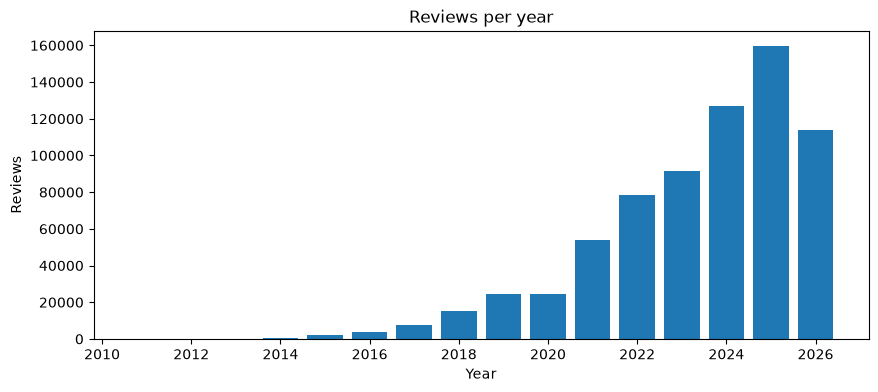

In [5]:
reviews_per_year = df["date"].dt.year.value_counts().sort_index()

plt.figure(figsize=(10, 4))
plt.bar(reviews_per_year.index, reviews_per_year.values)
plt.title("Reviews per year")
plt.xlabel("Year")
plt.ylabel("Reviews")
plt.show()

### 1.4 Review scores

One row per listing, so busy listings don't count twice

In [6]:
scores = ["review_scores_rating", "review_scores_cleanliness", "review_scores_communication",
          "review_scores_checkin", "review_scores_location"]
listing_scores = df.drop_duplicates("listing_id")[scores]
listing_scores.describe().round(2)

,review_scores_rating,review_scores_cleanliness,review_scores_communication,review_scores_checkin,review_scores_location
count,14247.00,14246.00,14246.00,14245.00,14245.00
mean,4.72,4.72,4.82,4.81,4.80
std,0.45,0.44,0.39,0.41,0.34
min,1.00,0.00,0.00,0.00,0.00
25%,4.67,4.65,4.80,4.79,4.75
50%,4.85,4.85,4.93,4.94,4.89
75%,4.98,4.98,5.00,5.00,5.00
max,5.00,5.00,5.00,5.00,5.00


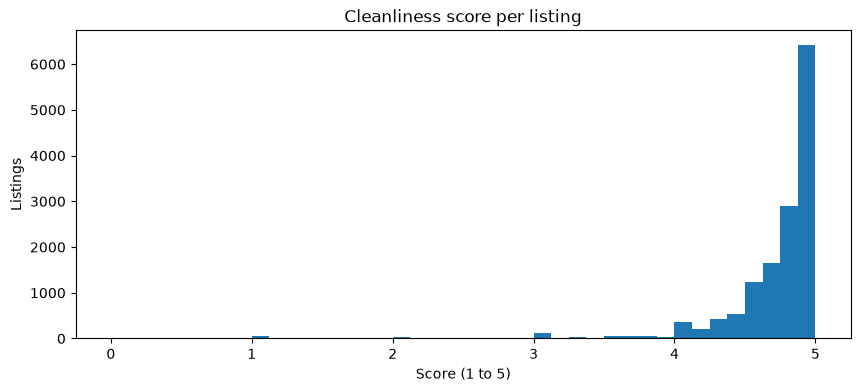

In [7]:
plt.figure(figsize=(10, 4))
plt.hist(listing_scores["review_scores_cleanliness"].dropna(), bins=40)
plt.title("Cleanliness score per listing")
plt.xlabel("Score (1 to 5)")
plt.ylabel("Listings")
plt.show()

### 1.5 Text length and language

count    703149.0
mean         36.8
std          40.1
min           1.0
25%          11.0
50%          24.0
75%          48.0
max        1298.0
Name: words, dtype: float64


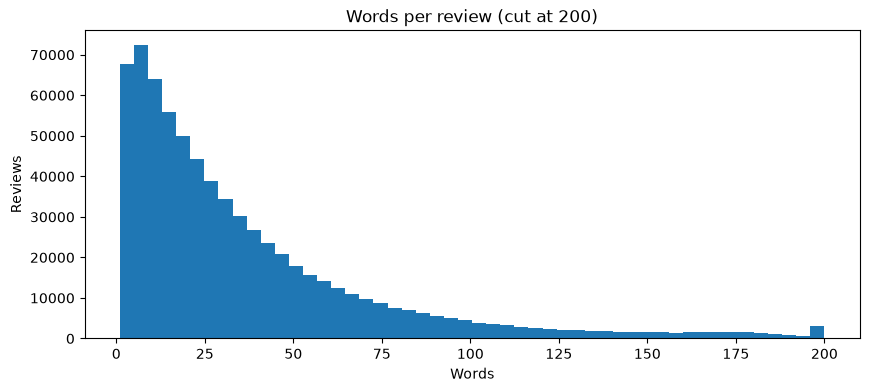

In [8]:
df["words"] = df["comments"].str.split().str.len()
print(df["words"].describe().round(1))

plt.figure(figsize=(10, 4))
plt.hist(df["words"].clip(upper=200), bins=50)
plt.title("Words per review (cut at 200)")
plt.xlabel("Words")
plt.ylabel("Reviews")
plt.show()

In [9]:
# Simple language check from src/preprocessing.py
df["english"] = df["comments"].apply(looks_english)

print("English:", round(df["english"].mean() * 100), "%")
print("5 words or less:", round((df["words"] <= 5).mean() * 100), "%")
print("With <br/> tags:", round(df["comments"].str.contains("<br").mean() * 100), "%")

English: 84 %
5 words or less: 12 %
With <br/> tags: 12 %


### 1.6 What a review looks like

Inside Airbnb asks people not to republish its data and this repo is public, so these are made-up reviews from `data/sample_mock.csv`, written in the same style

In [10]:
mock = pd.read_csv("../data/sample_mock.csv")
for text in mock["comments"].head(5):
    print("-", text)

- Great location, two blocks from the beach. The place was spotless and check-in was easy.
- The air conditioning stopped working on the second night and it took a day to get someone to fix it.
- Very noisy at night. Loud music from the neighbors until 2am and nobody answered when we called.
- Nice view and comfortable beds. A bit dusty in the bathroom but nothing major.
- We could not find the lockbox and waited an hour outside with our luggage. Instructions were confusing.


### Takeaways

- About 700,000 reviews of 14,000 listings, mostly from the last three years.
- Almost nothing is missing. Only 249 reviews have no text.
- Scores are all close to 5 (median cleanliness 4.85). They don't separate good homes from bad ones, so we need the text.
- Reviews are short, 24 words in the middle, and 12% are just a few words like "Great place!".
- 84% are in English. VADER and our stop words only work in English, so we keep English reviews from here on.

## 2. Text mining

### 2.1 Sample

30,000 random English reviews from 2023 on. Recent reviews matter most to the COO, and a sample keeps things fast

In [11]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud

recent = df[df["english"] & (df["date"] >= "2023-01-01")]
sample = recent.sample(30000, random_state=42).copy()

sample["text"] = sample["comments"].apply(strip_html)    # for VADER, keeps case and punctuation
sample["clean"] = sample["comments"].apply(clean_text)   # for word counts
print("English reviews since 2023:", len(recent), "| sample:", len(sample))

English reviews since 2023: 408181 | sample: 30000


### 2.2 Top words

Words that are in almost every review ("place", "stay", "great", "host") are added to the stop words

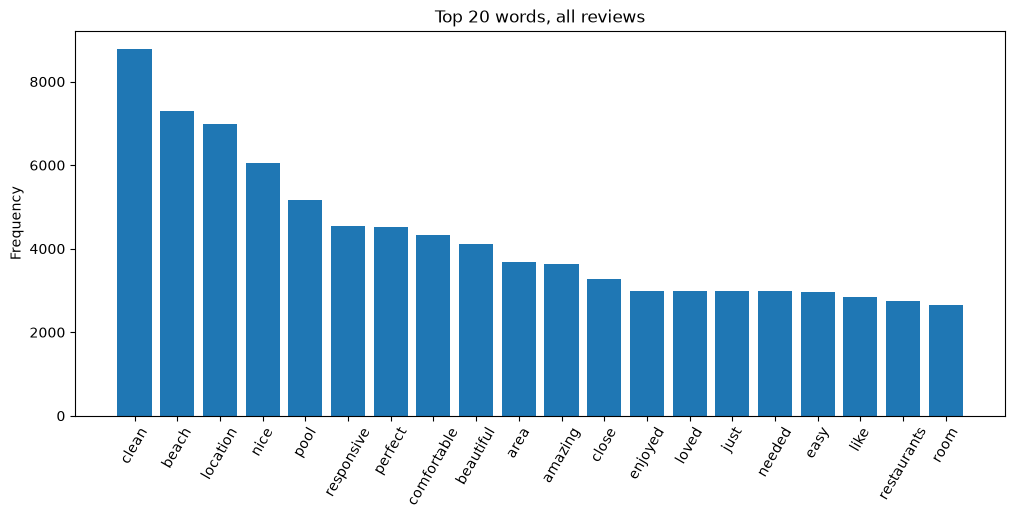

In [12]:
DOMAIN_STOP_WORDS = ["place", "stay", "great", "host", "home", "house", "airbnb", "would",
                     "definitely", "recommend", "everything", "really", "us", "also", "time"]
STOP_WORDS = list(ENGLISH_STOP_WORDS.union(DOMAIN_STOP_WORDS))

def top_words(texts, n=20, ngram_range=(1, 1), stop_words=STOP_WORDS):
    vectorizer = CountVectorizer(stop_words=stop_words, ngram_range=ngram_range, min_df=5)
    X = vectorizer.fit_transform(texts)
    counts = X.sum(axis=0).A1
    words = vectorizer.get_feature_names_out()
    return sorted(zip(words, counts), key=lambda x: x[1], reverse=True)[:n]

def plot_top_words(most_common, title):
    words, frequencies = zip(*most_common)
    plt.figure(figsize=(12, 5))
    plt.bar(words, frequencies)
    plt.title(title)
    plt.ylabel("Frequency")
    plt.xticks(rotation=60)
    plt.show()

plot_top_words(top_words(sample["clean"]), "Top 20 words, all reviews")

### 2.3 Sentiment with VADER

Compound score from -1 to +1. Below -0.05 is negative, above 0.05 is positive

sentiment
positive    95.4
negative     2.4
neutral      2.2
Name: proportion, dtype: float64


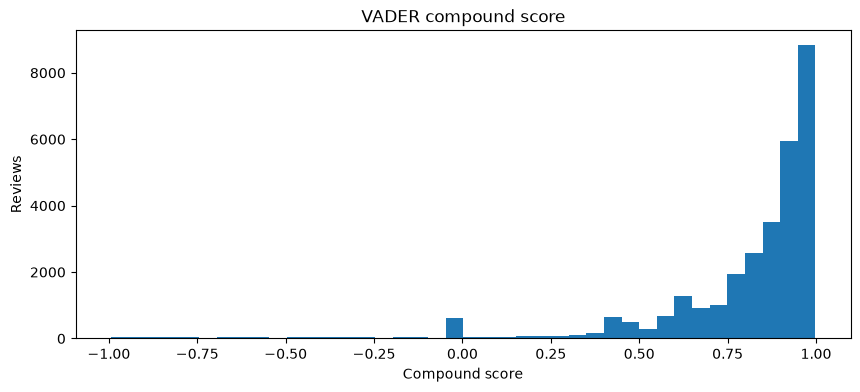

In [13]:
analyser = SentimentIntensityAnalyzer()
sample["compound"] = [analyser.polarity_scores(t)["compound"] for t in sample["text"]]

def vader_label(score):
    if score < -0.05:
        return "negative"
    if score > 0.05:
        return "positive"
    return "neutral"

sample["sentiment"] = sample["compound"].apply(vader_label)
sample["is_negative"] = sample["sentiment"] == "negative"
print((sample["sentiment"].value_counts(normalize=True) * 100).round(1))

plt.figure(figsize=(10, 4))
plt.hist(sample["compound"], bins=40)
plt.title("VADER compound score")
plt.xlabel("Compound score")
plt.ylabel("Reviews")
plt.show()

### 2.4 Negative reviews

Top words, top word pairs and a word cloud

Negative reviews: 708


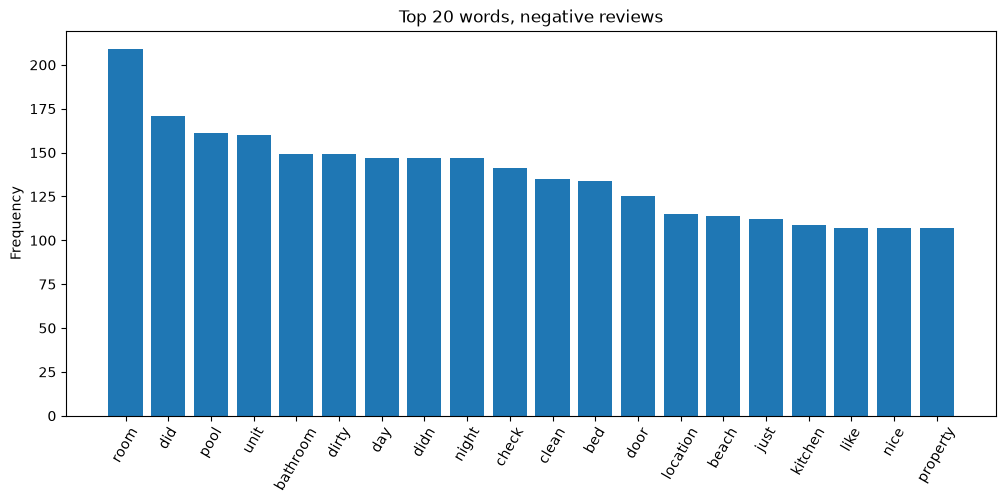

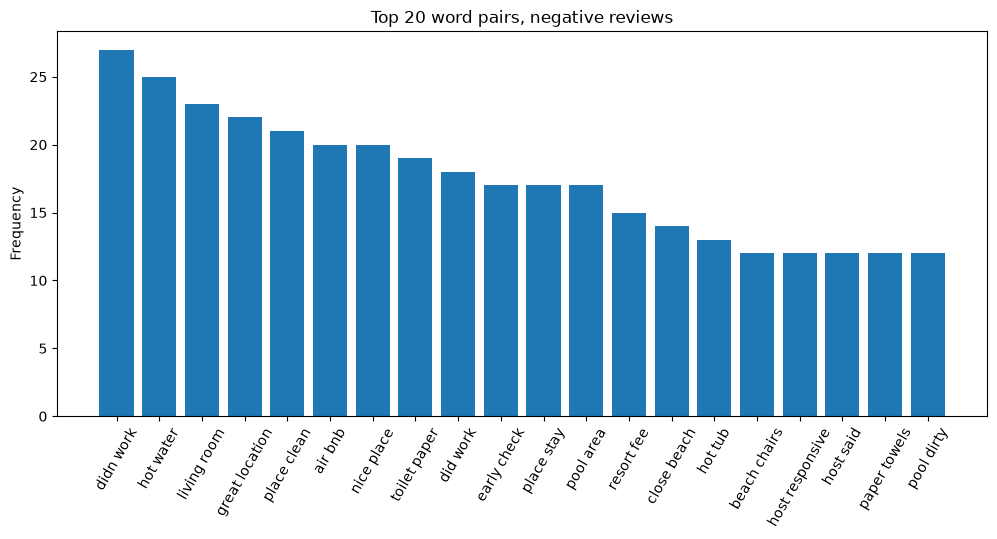

In [14]:
negative = sample[sample["is_negative"]]
print("Negative reviews:", len(negative))

plot_top_words(top_words(negative["clean"]), "Top 20 words, negative reviews")

# For pairs only the standard stop words are removed, so pairs like "didn work" stay in
plot_top_words(top_words(negative["clean"], ngram_range=(2, 2), stop_words="english"),
               "Top 20 word pairs, negative reviews")

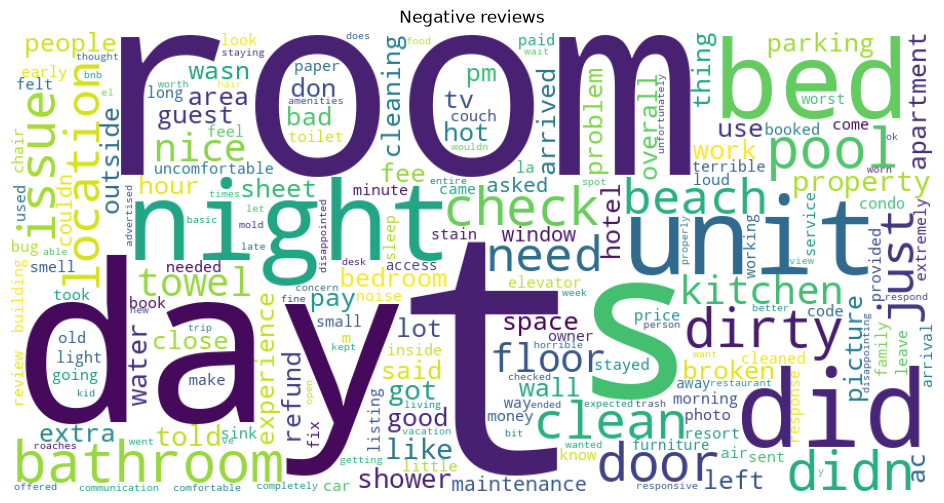

In [15]:
cloud = WordCloud(width=900, height=450, background_color="white", stopwords=set(STOP_WORDS),
                  collocations=False, random_state=42).generate(" ".join(negative["clean"]))
plt.figure(figsize=(12, 6))
plt.imshow(cloud)
plt.axis("off")
plt.title("Negative reviews")
plt.show()

### 2.5 Aspects, first look

A review mentions an aspect if it has one of its keywords. For each aspect: how often it comes up, how often those reviews are negative, and how much of all negative reviews it covers

In [16]:
ASPECT_WORDS = {
    "cleanliness": ["clean", "dirty", "filthy", "stain", "stains", "smell", "smelled", "smelly",
                    "dust", "dusty", "hair", "bugs", "roaches", "ants"],
    "maintenance": ["broken", "ac", "air conditioning", "leak", "leaking", "plumbing", "toilet", "shower",
                    "hot water", "wifi", "repair", "not working", "didn t work"],
    "host_communication": ["host", "communication", "responsive", "respond", "responded", "reply", "replied"],
    "check_in": ["check in", "checkin", "check out", "checkout", "key", "keys", "code", "lock", "lockbox"],
    "location": ["location", "located", "beach", "walk", "walking", "walkable", "close to", "restaurants", "downtown"],
    "noise": ["noise", "noisy", "loud", "quiet"],
}

rows = []
for aspect, words in ASPECT_WORDS.items():
    pattern = "|".join(r"\b" + w + r"\b" for w in words)   # whole words only
    mentioned = sample["clean"].str.contains(pattern, regex=True)
    rows.append({"aspect": aspect,
                 "mentioned_%": mentioned.mean() * 100,
                 "negative_%_when_mentioned": sample.loc[mentioned, "is_negative"].mean() * 100,
                 "share_of_negative_reviews_%": mentioned[sample["is_negative"]].mean() * 100})
aspects = pd.DataFrame(rows).set_index("aspect").round(1)
aspects

,mentioned_%,negative_%_when_mentioned,share_of_negative_reviews_%
aspect,,,
cleanliness,29.4,3.4,41.9
maintenance,5.3,13.4,30.2
host_communication,34.2,2.1,30.8
check_in,7.6,6.1,19.9
location,41.1,1.6,28.7
noise,9.8,2.6,10.7


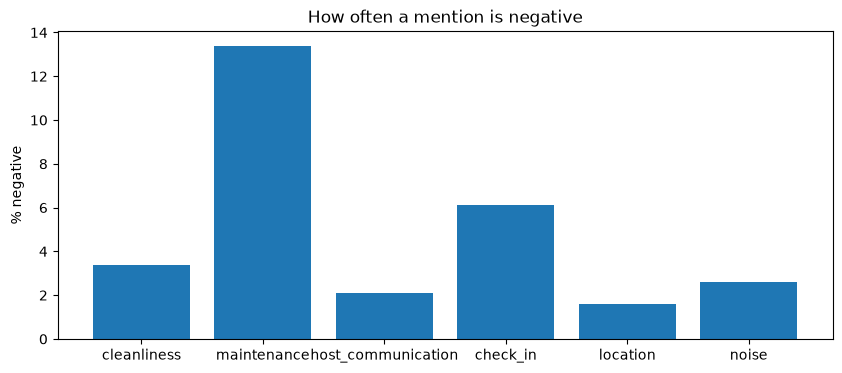

In [17]:
plt.figure(figsize=(10, 4))
plt.bar(aspects.index, aspects["negative_%_when_mentioned"])
plt.title("How often a mention is negative")
plt.ylabel("% negative")
plt.show()

### 2.6 Text vs. scores

Do listings with lower cleanliness scores get more negative reviews? Listings with at least 5 reviews in the sample

In [18]:
per_listing = sample.groupby("listing_id").agg(
    reviews=("is_negative", "size"),
    negative_share=("is_negative", "mean"),
    cleanliness=("review_scores_cleanliness", "first"))
per_listing = per_listing[per_listing["reviews"] >= 5].copy()

def score_band(score):
    if score < 4.5:
        return "1. below 4.5"
    if score <= 4.8:
        return "2. 4.5 to 4.8"
    return "3. above 4.8"

per_listing["band"] = per_listing["cleanliness"].apply(score_band)
print("Listings:", len(per_listing))
print("Correlation:", round(per_listing["negative_share"].corr(per_listing["cleanliness"]), 2))
(per_listing.groupby("band")["negative_share"].mean() * 100).round(1)

Listings: 2207
Correlation: -0.24


band
1. below 4.5     5.3
2. 4.5 to 4.8    3.3
3. above 4.8     1.2
Name: negative_share, dtype: float64

### 2.7 Negative reviews by area

In [19]:
top_areas = sample["neighbourhood_cleansed"].value_counts().head(8).index
by_area = sample[sample["neighbourhood_cleansed"].isin(top_areas)]
(by_area.groupby("neighbourhood_cleansed")["is_negative"].mean() * 100).round(1).sort_values(ascending=False)

neighbourhood_cleansed
Hallandale Beach    4.4
Dania Beach         3.1
Hollywood           3.1
Fort Lauderdale     2.0
Oakland Park        1.9
Pompano Beach       1.8
Wilton Manors       1.8
Deerfield Beach     1.5
Name: is_negative, dtype: float64

### Takeaways

- The top words are praise: clean, beach, location, pool, responsive.
- VADER calls 95% of the reviews positive and only 2.4% negative (708 of 30,000). Complaints are rare, so in Phase 3 we will add extra low-scoring reviews to the sample.
- Negative reviews point to real problems: "didn work", "hot water", "toilet paper", "pool dirty", "resort fee".
- Cleanliness is in 42% of the negative reviews, the biggest complaint. Maintenance comes up less, but 13% of those reviews are negative, the highest rate.
- The text matches the scores. Listings with cleanliness below 4.5 get 5.3% negative reviews, against 1.2% above 4.8.
- Some areas do worse. Hallandale Beach has 4.4% negative reviews, twice Fort Lauderdale's 2.0%.
- The keyword rule is rough: "clean" counts whether the guest liked it or not. That is why Phase 3 uses Claude.
- We skip topic modeling. Our reviews are very short (24 words) and we already know the aspects we want.

## 3. Plan for Phase 3

### 3.1 Path B

The COO doesn't need us to predict a cleanliness score, the score already exists. The COO needs to know what guests complain about, where and when. Section 1 showed the scores don't separate homes, and section 2 showed the text does. So Phase 3 is about patterns and recommendations, like "maintenance complaints are highest in area X in summer".

### 3.2 What Claude will do

- For each review, label each aspect as positive, negative or not mentioned, with a short quote: cleanliness, maintenance, host communication, check-in, location, plus noise and parking (see 3.3).
- About 1,500 English reviews from 2023 on: 1,000 random and 500 extra with low VADER scores, weighted back when we report percentages.
- We hand-label 100 of them and report how often we agree with Claude.
- Then we compare negative mentions by area, type of home and season.

### 3.3 Prompt test

On the 12 made-up reviews, so no real review is sent out and the results can be public. Each one was written with a known problem, so we know what to expect

In [20]:
import os
import json
import anthropic
from dotenv import load_dotenv

ASPECT_DEFINITIONS = {
    "cleanliness": "how clean the place was: dirt, stains, smells, bugs, or praise for being clean or spotless",
    "maintenance": "things that work or are broken: air conditioning, plumbing, hot water, appliances, wifi, pool equipment",
    "host_communication": "how the host or manager responded: speed, helpfulness, answering calls or messages",
    "check_in": "getting in and out: instructions, keys, lockbox or door codes, check-in and check-out times",
    "location": "where the home is: distance to the beach, restaurants, shops, safety of the area",
}

# JSON schema, as in Class 13: Claude must answer every aspect with one of three labels
aspect_schema = {
    "type": "object",
    "properties": {aspect: {"type": "object",
                            "properties": {"sentiment": {"type": "string",
                                                         "enum": ["positive", "negative", "not_mentioned"]},
                                           "evidence": {"type": "string"}},
                            "required": ["sentiment", "evidence"],
                            "additionalProperties": False}
                   for aspect in ASPECT_DEFINITIONS},
    "required": list(ASPECT_DEFINITIONS),
    "additionalProperties": False,
}

PROMPT = '''You label guest reviews of short-term rental homes for the operations team.
For each aspect below, decide if the review is positive, negative, or does not mention it.

Aspects:
{aspects}

Rules:
- Use "not_mentioned" unless the review says something about that aspect.
- A review can be positive about one aspect and negative about another.
- For evidence, quote the exact words from the review, or leave it empty if not mentioned.

<review>
{review}
</review>'''

MODEL = "claude-haiku-5-5"
PRICES = (0.10, 0.50)   # USD per 1 million input and output tokens (class notebook)

def label_review(client, review):
    aspects = "\n".join(f"- {name}: {meaning}" for name, meaning in ASPECT_DEFINITIONS.items())
    response = client.messages.create(
        model=MODEL,
        max_tokens=1024,
        messages=[{"role": "user", "content": PROMPT.format(aspects=aspects, review=review)}],
        output_config={"effort": "low", "format": {"type": "json_schema", "schema": aspect_schema}},
    )
    text = next(block.text for block in response.content if block.type == "text")
    return json.loads(text), response.usage

In [21]:
# Saved after the first run, so running the notebook again costs nothing.
# Needs ANTHROPIC_API_KEY in a .env file; without it the cell skips.
RESULTS_FILE = "../data/claude_prompt_test_mock.json"
load_dotenv(override=True)   # the key in .env wins over an old one saved in Windows

if os.path.exists(RESULTS_FILE):
    test = json.load(open(RESULTS_FILE))
    print("Loaded saved test results")
elif os.getenv("ANTHROPIC_API_KEY"):
    client = anthropic.Anthropic()
    test = []
    for row in mock.itertuples():
        labels, usage = label_review(client, row.comments)
        test.append({"id": row.id, "labels": labels,
                     "input_tokens": usage.input_tokens, "output_tokens": usage.output_tokens})
    json.dump(test, open(RESULTS_FILE, "w"), indent=1)
    print("Labeled", len(test), "made-up reviews and saved the results")
else:
    test = []
    print("No API key found, skipping the Claude test")

Loaded saved test results


In [22]:
# What we expect for each made-up review, to compare with Claude
EXPECTED = {
    9000001: {"cleanliness": "positive", "check_in": "positive", "location": "positive"},
    9000002: {"maintenance": "negative"},
    9000003: {"host_communication": "negative"},
    9000004: {"cleanliness": "negative"},
    9000005: {"check_in": "negative"},
    9000006: {"cleanliness": "positive"},
    9000007: {"cleanliness": "negative"},
    9000008: {},
    9000009: {"host_communication": "positive", "maintenance": "positive"},
    9000010: {},
    9000011: {"maintenance": "negative"},
    9000012: {"cleanliness": "positive"},
}

if test:
    rows = []
    for result in test:
        for aspect in ASPECT_DEFINITIONS:
            rows.append({"id": result["id"], "aspect": aspect,
                         "expected": EXPECTED[result["id"]].get(aspect, "not_mentioned"),
                         "claude": result["labels"][aspect]["sentiment"]})
    check = pd.DataFrame(rows)
    check["agree"] = check["expected"] == check["claude"]
    print("Claude agrees with us on", round(check["agree"].mean() * 100), "% of", len(check), "decisions")
    display(check.pivot(index="id", columns="aspect", values="claude"))
    display(check[~check["agree"]])

Claude agrees with us on 95 % of 60 decisions


aspect,check_in,cleanliness,host_communication,location,maintenance
id,,,,,
9000001,positive,positive,not_mentioned,positive,not_mentioned
9000002,not_mentioned,not_mentioned,negative,not_mentioned,negative
9000003,not_mentioned,not_mentioned,negative,negative,not_mentioned
9000004,not_mentioned,negative,not_mentioned,not_mentioned,not_mentioned
9000005,negative,not_mentioned,not_mentioned,not_mentioned,not_mentioned
9000006,not_mentioned,positive,not_mentioned,not_mentioned,not_mentioned
9000007,not_mentioned,negative,not_mentioned,not_mentioned,not_mentioned
9000008,not_mentioned,not_mentioned,not_mentioned,not_mentioned,not_mentioned
9000009,not_mentioned,not_mentioned,positive,not_mentioned,positive


,id,aspect,expected,claude,agree
7,9000002,host_communication,not_mentioned,negative,False
14,9000003,location,not_mentioned,negative,False
49,9000010,location,not_mentioned,negative,False


In [23]:
# Cost from the real token counts
if test:
    tokens_in = sum(r["input_tokens"] for r in test) / len(test)
    tokens_out = sum(r["output_tokens"] for r in test) / len(test)
    per_review = (tokens_in * PRICES[0] + tokens_out * PRICES[1]) / 1e6
    print(f"Per review: {tokens_in:.0f} input + {tokens_out:.0f} output tokens = ${per_review:.5f}")
    print(f"1,500 reviews: about ${1500 * per_review:.2f}")
    print(f"All {len(recent):,} recent English reviews: about ${len(recent) * per_review:.2f}")

Per review: 1242 input + 152 output tokens = $0.00020
1,500 reviews: about $0.30
All 408,181 recent English reviews: about $81.78


### What the test showed

- Claude agreed with us on 95% of the 60 decisions (12 reviews, 5 aspects).
- "It took a day to get someone to fix it": Claude also marked the host as negative. Fair, our expected label was too strict.
- "Very noisy at night" and "Parking was a nightmare" ended up under location, because we had no noise or parking aspect. We will add both.
- About \$0.0002 per review, so 1,500 reviews cost about \$0.30.

### 3.4 Concerns

- **Privacy.** The raw data stays out of this public repo and the notebook only shows counts, charts and made-up examples. Claude gets the review text only, no names. The API key sits in `.env`, which `.gitignore` keeps off GitHub.
- **Cost and scale.** We don't need all 400,000 reviews. About 1,500 are enough to compare areas and seasons, for well under a dollar.
- **Is Claude right?** We hand-check 100 reviews, keep the evidence quotes and use a fixed list of aspects so runs stay consistent.
- **Rare complaints.** Only 2.4% of reviews are negative, so we oversample low VADER scores and weight back when we report.

## 4. Phase 2 update

**Done.** Path B is set. We explored 703,149 reviews, wrote reusable cleaning functions (`src/preprocessing.py`), ran keyword, sentiment and aspect baselines on 30,000 recent English reviews, and tested the Claude prompt on 12 made-up reviews (95% agreement).

**Found.** Only 2.4% of reviews are negative. Cleanliness is the most common complaint, maintenance the most likely to be negative, and listings with lower cleanliness scores get about four times as many negative reviews.

**Next.** Label about 1,500 reviews with Claude, hand-check 100, and break down complaints by area, type of home and season.

**Team.** Guilherme did the code and analysis. Manoj cloned the repo, reviewed the plan and committed from his machine.

## AI Use Log

Tool: Claude (Claude Code), as a coding assistant.

- Claude drafted the helper functions and the notebook cells, using the methods from class (CountVectorizer, VADER, word clouds, the JSON schema prompt from Class 13). We ran every cell and checked the outputs.
- Claude drafted the text from our outputs, and we checked each number.
- Error caught: an early version printed three real reviews. This repo is public and Inside Airbnb asks people not to republish its data, so we switched to made-up examples.
- The Claude API test in 3.3 ran from our own notebook with the class project key, on made-up reviews only.